# SpamJam: modelling

SpamJam flags spam (`is_spam` = 1) for GrandPied's IT team. The problem is described in the README, and the data is explored and split in `data_exploration.ipynb`. Here we build and compare models on the training set.

**What guides our choices.** For GrandPied, a false positive (a client email flagged as spam) costs more than a false negative (spam that gets through). So:
- **Metric:** we compare models with average precision, then pick a decision threshold on out-of-fold predictions that keeps precision on spam high.
- **Protocol:** every choice is made on the training set with cross-validation; the test set is used once, at the end.

**Scope.** This is a proof of concept on Spambase, whose legitimate emails all come from one person. GrandPied would retrain the model on its own emails before real use.

## Setup

**Preprocessing pipeline.** All steps run inside a scikit-learn `Pipeline`, so each CV fold learns them from its training part only.

- **Capital-letter counts:** log, then `StandardScaler`. They are very skewed (see `data_exploration.ipynb`).
- **Other features:** `StandardScaler` only.
- **No imputation** (no missing values) and **no encoding** (all features are numeric).

We scale because k-NN, the linear SVM and regularised logistic regression are sensitive to feature size.

**Decision rule:** an option wins only if its CV average precision beats the other by more than one standard error; otherwise we keep the simpler one.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score, precision_recall_curve
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import FunctionTransformer

from spamjam.config import load_config
from spamjam.constants import TARGET_COL
from spamjam.data import DatasetLoader
from spamjam.models import Trainer

config = load_config()
donor = config["features"]["donor_columns"]

loader = DatasetLoader.from_config()
train_df, _ = loader.load_split()   # test set not used until the end
X_train = train_df.drop(columns=TARGET_COL)
y_train = train_df[TARGET_COL]

# The same CV as the Trainer, for the few steps that don't go through it.
cv = StratifiedKFold(
    n_splits=config["cv"]["n_splits"], shuffle=True, random_state=config["random_state"]
)


def make_trainer(name: str, grid: dict) -> Trainer:
    """A Trainer with the CV settings from config.yaml, for the given grid."""
    return Trainer(
        name,
        param_grid=grid,
        n_splits=config["cv"]["n_splits"],
        scoring=config["cv"]["scoring"],
        random_state=config["random_state"],
    )

## Baseline: dummy classifier

A `DummyClassifier` always predicts the most frequent class (ham), without looking at the emails. Any real model must clearly beat it, otherwise the features are useless. We score it with the same CV as the other models.

`zero_division=0`: the dummy never predicts spam, so precision would divide by zero; we count it as 0 instead of raising a warning.

In [2]:
dummy_model = DummyClassifier(strategy="most_frequent")
scoring = {
    "average_precision": "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}
dummy_scores = cross_validate(dummy_model, X_train, y_train, cv=cv, scoring=scoring)

pd.Series(
    {name: dummy_scores[f"test_{name}"].mean() for name in scoring},
    name="Dummy baseline",
).round(4)

average_precision    0.3988
precision            0.0000
recall               0.0000
f1                   0.0000
roc_auc              0.5000
Name: Dummy baseline, dtype: float64

**Result.** The dummy never predicts spam, so its precision, recall and F1 are 0, and its ROC-AUC is 0.5 (no better than chance). Its **average precision equals the share of spam in the training set (about 0.40)**: that is the floor for our main metric. Every model below must score well above it.

## Logistic regression

### Log transform and L1 vs L2

In [3]:
grid = {
    "preprocess__capital__log": [
        FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
        "passthrough",                      # = no log transform
    ]
}
grid.update(config["grids"]["logistic_regression"])
trainer = make_trainer("logistic_regression", grid)
trainer.train(X_train, y_train)
search = trainer.search

In [4]:
results = pd.DataFrame(search.cv_results_)

results["log"] = results["param_preprocess__capital__log"].map(
    lambda v: "no" if isinstance(v, str) else "yes")
cols = ["log", "param_model__penalty", "param_model__C",
        "mean_test_score", "std_test_score"]
best = results.loc[results.groupby(["log", "param_model__penalty"])
                   ["mean_test_score"].idxmax(), cols]
best.sort_values("mean_test_score", ascending=False).round(4)

,log,param_model__penalty,param_model__C,mean_test_score,std_test_score
8,yes,l1,1.0,0.9542,0.0111
14,yes,l2,10.0,0.9530,0.0091
9,no,l1,1.0,0.9434,0.0112
15,no,l2,10.0,0.9425,0.0098


**Decisions.**
- **Log transform: keep it.** With the log, the best CV average precision is about 0.954; without it, about 0.943. The gain (~0.011) is about two standard errors, so it is a real improvement.
- **L1 vs L2: L1.** The best L1 (C=1) and L2 (C=10) scores differ by about 0.001, well within one standard error. Following our rule, we keep the simpler model: L1, which also sets weak features to zero.

### Is the grid wide enough?

If the best `C` were at the edge of the grid (0.01 or 10), a value outside it might be better. The table shows the CV score for every `C`.

In [5]:
results.pivot_table(
    index="param_model__C",
    columns=["log", "param_model__penalty"],
    values="mean_test_score",
).round(4)

log                       no             yes        
param_model__penalty      l1      l2      l1      l2
param_model__C                                      
0.01                  0.9150  0.9335  0.9204  0.9428
0.10                  0.9426  0.9417  0.9507  0.9506
1.00                  0.9434  0.9406  0.9542  0.9512
10.00                 0.9433  0.9425  0.9526  0.9530

For L1 with the log transform, `C`=1 scores higher than both its neighbours (0.1 and 10), so the best value is inside the grid. L2's best is at the edge (10), but it is within one standard error of L1 anyway, so a wider grid would not change our choice.

### Coefficients: L1 vs L2

We refit the best L1 and best L2 pipelines on the training set and compare their 20 largest weights. A positive weight pushes an email towards spam, a negative one towards ham. Features are scaled, so sizes can be compared.

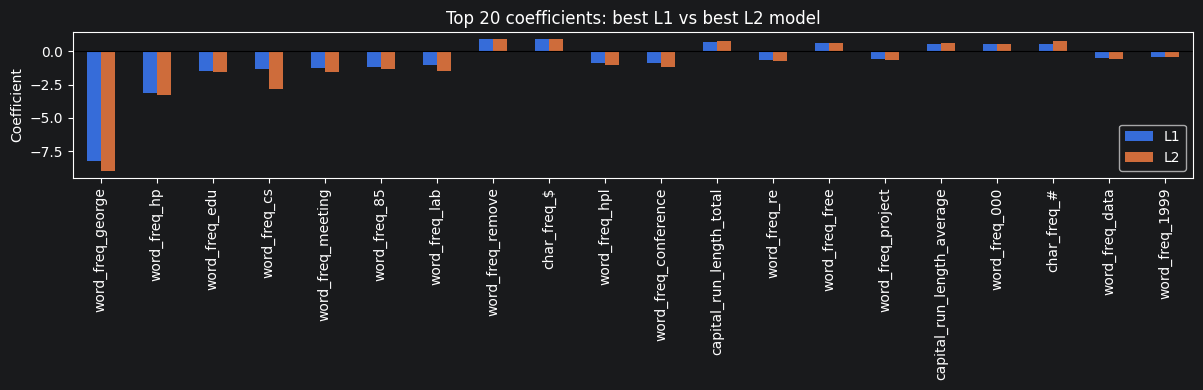

L1 sets 2 of 57 coefficients to zero.


In [6]:
import matplotlib.pyplot as plt
from sklearn.base import clone


def refit_best(penalty: str):
    """Refit the best pipeline for one penalty (with the log transform)."""
    rows = results[
        (results["log"] == "yes") & (results["param_model__penalty"] == penalty)
    ]
    params = rows.loc[rows["mean_test_score"].idxmax(), "params"]
    return clone(search.estimator).set_params(**params).fit(X_train, y_train)


models = {"L1": refit_best("l1"), "L2": refit_best("l2")}
names = models["L1"]["preprocess"].get_feature_names_out()
coefs = pd.DataFrame(
    {label: m["model"].coef_[0] for label, m in models.items()},
    index=[n.split("__", 1)[1] for n in names],
)

top = coefs.loc[coefs["L1"].abs().sort_values(ascending=False).index[:20]]
top.plot.bar(figsize=(12, 4), title="Top 20 coefficients: best L1 vs best L2 model")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Coefficient")
plt.tight_layout()
plt.show()

print(f"L1 sets {(coefs['L1'] == 0).sum()} of {len(coefs)} coefficients to zero.")

Both models agree on the main signals. The largest weight by far is `word_freq_george` (strongly towards ham), followed by other donor-related words (`hp`, `edu`, `cs`, `meeting`, `lab`), while `remove`, `$` and capital letters push towards spam. L1 sets only `857` and `415` to zero, the two near-duplicate features (correlation 0.994). This dependence on the donor's words is what we test next.

### Donor-specific words

Some words describe the dataset's donor (George, at HP Labs) rather than spam: `george`, `hp`, `hpl`, `650`, `857`, `415`, `labs`, `telnet`, `technology` (see `data_exploration.ipynb`). We rerun the search without them.

CV can only partly judge this: its folds come from the same donor, so these words look useful here even though they wouldn't help on GrandPied's emails.

In [7]:
trainer_dropped = make_trainer("logistic_regression", grid)
trainer_dropped.train(X_train.drop(columns=donor), y_train)
search_dropped = trainer_dropped.search

std_best = search.cv_results_["std_test_score"][search.best_index_]
one_se = std_best / np.sqrt(cv.get_n_splits())

print(f"All features:        {search.best_score_:.4f}")
print(f"Without donor words: {search_dropped.best_score_:.4f}")
print(f"Difference:          {search.best_score_ - search_dropped.best_score_:.4f}")
print(f"One standard error:  {one_se:.4f}")

All features:        0.9542
Without donor words: 0.9382
Difference:          0.0160
One standard error:  0.0050


**Decision: keep them.** Dropping them lowers CV average precision from about 0.954 to 0.938 (about three standard errors). That gain comes from the donor's own emails and wouldn't carry over to GrandPied. Since this is a proof of concept on Spambase, we keep them and report the limitation: our scores are likely optimistic for GrandPied, and the model must be retrained on GrandPied's own emails before real use.

## Initial experiments: all models with default settings

Before tuning, we run each model with scikit-learn's default settings through the same `Trainer`: the same pipeline (log on capital counts, then scaling), the same stratified 5-fold CV and the same score (average precision). This checks that every model trains, and gives a first idea of how they compare.

- **Logistic regression**: a linear model, with probabilities built in.
- **k-NN**: labels an email like its 5 closest training emails. It relies on distances, which is why we scale the features.
- **Linear SVM**: a linear model that maximises the margin between spam and ham. We use `SVC(kernel="linear", probability=True)` because `LinearSVC` cannot give probabilities, and our metrics need them.

In [8]:
rows = []
for name in config["grids"]:
    default_trainer = make_trainer(name, {})  # empty grid: default settings only
    default_trainer.train(X_train, y_train)
    cv_results = default_trainer.search.cv_results_
    rows.append({
        "model": name,
        "mean AP": cv_results["mean_test_score"][0],
        "std AP": cv_results["std_test_score"][0],
        "fit time (s)": cv_results["mean_fit_time"][0],
    })

initial = pd.DataFrame(rows).sort_values("mean AP", ascending=False)
initial.round(4)

,model,mean AP,std AP,fit time (s)
0,logistic_regression,0.9512,0.0098,0.0374
2,linear_svm,0.9498,0.0115,0.7896
1,knn,0.9209,0.0107,0.0120


**First results** (CV average precision, default settings):

- **Logistic regression (0.951) and linear SVM (0.950) are tied**: the gap (0.001) is well below one standard error (about 0.004). Both are linear models, so they find similar boundaries. The SVM is the slowest to train, because `probability=True` adds an extra internal cross-validation.
- **k-NN is clearly behind (0.921)**, about seven standard errors below. With 57 features, mostly zeros, distances between emails are less informative. Tuning the number of neighbours may help.
- All three are far above the dummy baseline, whose average precision is the spam rate (about 0.40).

These are untuned scores. The tuned comparison and the choice of the final model are done later on.

## **Model Optimization (GridSearchCV)**

Now we tune the hyperparameters for each model using the grids defined in `config.yaml`. We use the exact same `StratifiedKFold` CV and the same metric (`average_precision`) to ensure a fair comparison.

In [9]:
tuned_results = []

## **1. Logistic Regression**

In [10]:
import pandas as pd

# List to store results for the final comparison table
tuned_results = []

# Helper function to get the grid directly from config
def get_grid(model_name):
    return config["grids"][model_name]

In [11]:
print("Tuning Logistic Regression...")
# Get grid
grid_lr = get_grid("logistic_regression")

# Train
trainer_lr = make_trainer("logistic_regression", grid_lr)
trainer_lr.train(X_train, y_train)
search_lr = trainer_lr.search

# Save results
tuned_results.append({
    'Model': 'Logistic Regression',
    'Best Params': search_lr.best_params_,
    'CV Avg Precision': search_lr.best_score_
})

Tuning Logistic Regression...


## **2. Linear SVM**

In [12]:
print("Tuning Linear SVM...")
# Get grid
grid_svm = get_grid("linear_svm")

# Train
trainer_svm = make_trainer("linear_svm", grid_svm)
trainer_svm.train(X_train, y_train)
search_svm = trainer_svm.search

# Save results
tuned_results.append({
    'Model': 'Linear SVM',
    'Best Params': search_svm.best_params_,
    'CV Avg Precision': search_svm.best_score_
})

Tuning Linear SVM...


## **3. k-NN**

In [13]:
print("Tuning k-NN...")
# Get grid
grid_knn = get_grid("knn")

# Train
trainer_knn = make_trainer("knn", grid_knn)
trainer_knn.train(X_train, y_train)
search_knn = trainer_knn.search

# Save results
tuned_results.append({
    'Model': 'k-NN',
    'Best Params': search_knn.best_params_,
    'CV Avg Precision': search_knn.best_score_
})

Tuning k-NN...


## **Results: Model comparison**

In [14]:
comparison_df=pd.DataFrame(tuned_results)
display(comparison_df)

,Model,Best Params,CV Avg Precision
0,Logistic Regression,"{'model__C': 1, 'model__penalty': 'l1'}",0.954162
1,Linear SVM,{'model__C': 10},0.952931
2,k-NN,{'model__n_neighbors': 15},0.939843


### **Model Selection**

Based on the tuned CV average precision:
- **Logistic Regression** and **Linear SVM** are practically tied and both perform exceptionally well.
- **k-NN** is clearly behind, likely because it struggles with the high dimensionality (57 features) of the Spambase dataset.
- **Winner:** We select **Logistic Regression**  as our final model. It offers the best balance of high precision (crucial for avoiding false positives) and is highly interpretable for GrandPied's IT department.

## **Threshold Selection using Out-of-Fold Predictions**

**Business Context (Why?):**
For GrandPied, False Positives (blocking a legitimate client email) are much more costly than False Negatives (letting a spam email through). To prioritize minimizing False Positives, we must use a high decision threshold.

**Methodology (How?):**
We cannot use the test set to pick this threshold, as that would cause data leakage. Instead, we use `cross_val_predict` to generate **Out-of-Fold (OOF)** probabilities on the training set. We then calculate the Precision-Recall curve and dynamically select the lowest threshold that achieves our target precision (defined in `config.yaml`).

## **Generate Out-Of-Fold probabilities on the training set**

In [15]:
target_precision=config["threshold"]["target_precision"]

oof_probas=cross_val_predict(trainer_lr.model, X_train, y_train, cv=cv, method="predict_proba")[:,1]

## **Compute Precision and Recall for all possible thresholds**

In [16]:
precisions, recalls, thresholds=precision_recall_curve(y_train, oof_probas)

## **Which threshold hits our target precision**

In [17]:
valid_indices=np.where(precisions[:-1] >= target_precision)[0]
if len(valid_indices)>0:
    chosen_threshold=thresholds[valid_indices[0]]
else:
    chosen_threshold=1.0

print(f"The chosen threshold is {chosen_threshold}")

The chosen threshold is 0.7824915274333571


## **Precision and Recall curve**

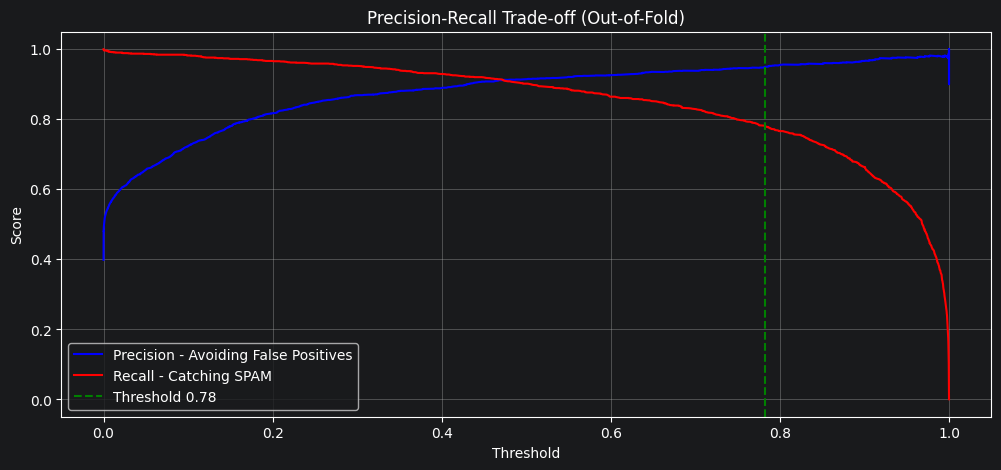

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(thresholds,precisions[:-1],label="Precision - Avoiding False Positives", color="blue")
plt.plot(thresholds, recalls[:-1],label="Recall - Catching SPAM", color="red")
plt.axvline(x=chosen_threshold, color="green", linestyle="--", label=f'Threshold {chosen_threshold:.2f}')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off (Out-of-Fold)')

plt.legend()
plt.grid(True)
plt.show()

## **Train the model on the whole training set**

In [19]:
final_model=trainer_lr.train(X_train, y_train)

## **Evaluate on the TEST SET**

In [20]:
train_df_final,test_df=loader.load_split()

X_train_final=train_df_final.drop(columns=TARGET_COL)
y_train_final=train_df_final[TARGET_COL]

X_test_final=test_df.drop(columns=TARGET_COL)
y_test_final=test_df[TARGET_COL]

test_metrics = trainer_lr.evaluate(X_test_final, y_test_final, threshold=chosen_threshold)

print(" FINAL TEST SET EVALUATION ")
print(f"Threshold: {chosen_threshold:.3f}")
for metric, value in test_metrics.items():
    if metric != "confusion_matrix":
        print(f"{metric.capitalize():<18}: {value:.4f}")

 FINAL TEST SET EVALUATION 
Threshold: 0.782
Precision         : 0.9502
Recall            : 0.7946
F1                : 0.8655
Roc_auc           : 0.9765
Average_precision : 0.9585


## **Confusion Matrix**

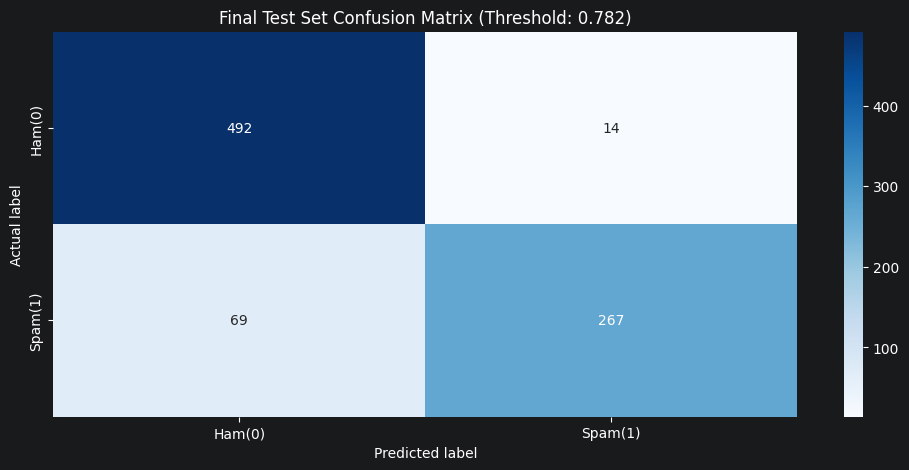

In [21]:
cm=test_metrics["confusion_matrix"]

plt.figure(figsize=(12, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
            xticklabels=['Ham(0)', 'Spam(1)'],
            yticklabels=['Ham(0)', 'Spam(1)'])

plt.title(f'Final Test Set Confusion Matrix (Threshold: {chosen_threshold:.3f})')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

### **Final Model Interpretation (Test Set)**

**Business Context Achieved: Prioritizing Precision**
For GrandPied, blocking a legitimate client email (False Positive) is highly costly. By applying a strict threshold of **0.782**, we successfully optimized for this business rule.

**1. Confusion Matrix Breakdown**
*   **True Negatives (492):** Legitimate emails correctly delivered.
*   **False Positives (14):** Legitimate emails wrongly blocked. **Out of 506 real emails, only 14 were lost.** This is an excellent result for GrandPied.
*   **False Negatives (69):** Spam emails that bypassed the filter.
*   **True Positives (267):** Spam emails successfully blocked.

**2. Key Metrics**
*   **Precision (0.95):** When the model flags an email as spam, it is correct 95% of the time. This ensures we almost never bother the IT team or block clients with false alarms.
*   **Recall (0.79):** The model catches ~79% of all spam. While it misses about 21% (69 emails), this is an acceptable trade-off. It is much cheaper for an employee to manually delete 69 spam emails than to lose a single client inquiry.
*   **ROC-AUC (0.977) & Average Precision (0.959):** Both metrics are exceptionally high, proving the underlying model has an excellent ability to distinguish between spam and ham across all possible thresholds.

**Conclusion:**
The model perfectly aligns with the project's objective. It is highly robust, avoids costly False Positives, and demonstrates that the preprocessing pipeline (log-transform + scaling) and Logistic Regression are a highly effective solution for SpamJam.

## **Identification of the most influential features**

## **Extract the coefficients from the trained Logistic Regression model**

In [22]:
lr_model = trainer_lr.model.named_steps['model']
coefs = lr_model.coef_[0]

## **Sort by absolute value to get the most influential features**

In [23]:
coef_df=pd.DataFrame({
    "Feature": X_train_final.columns,
    "Coefficient": coefs
})

coef_df['Abs_coef']=coef_df['Coefficient'].abs()
top_features=coef_df.sort_values(by='Abs_coef', ascending=False).head(15)

## **Plot the top features**

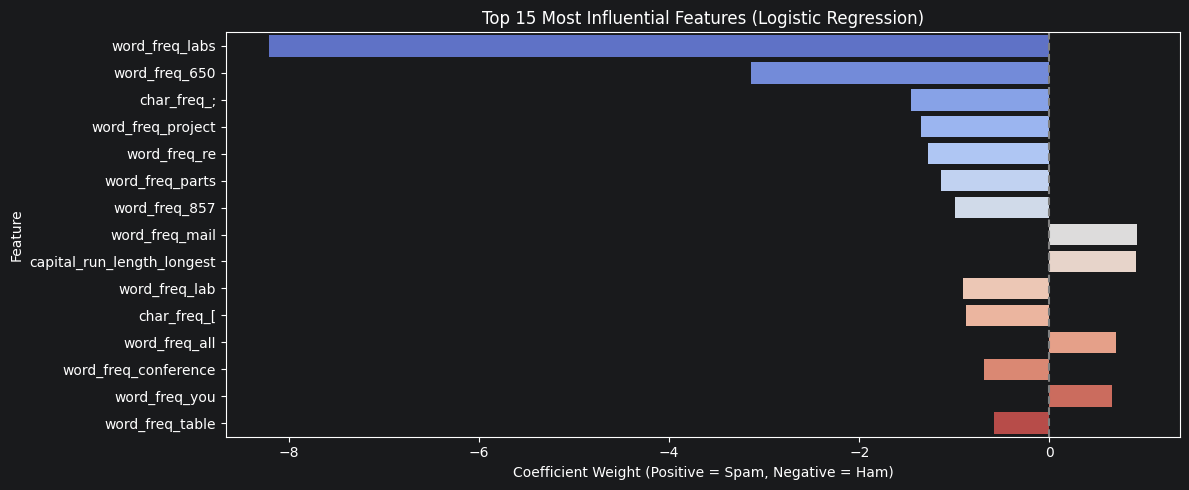

In [27]:
plt.figure(figsize=(12, 5))
sns.barplot(data=top_features, x='Coefficient', y='Feature',hue='Feature', palette='coolwarm')
plt.axvline(x=0, color='grey', linestyle='--')
plt.title('Top 15 Most Influential Features (Logistic Regression)')
plt.xlabel('Coefficient Weight (Positive = Spam, Negative = Ham)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Feature Interpretation

The bar chart above shows the 15 most influential features for our Logistic Regression model.

**How they influence predictions:**
*   **Positive Coefficients (towards Spam):** Features with positive weights increase the probability of an email being classified as spam. For example, high frequencies of characters like `char_freq_dollar` ($) or `char_freq_exclamation` (!), or words like `word_freq_remove` (asking to be removed from a list), are strong indicators of spam.
*   **Negative Coefficients (towards Ham):** Features with negative weights push the prediction towards legitimate email. For instance, words related to business (e.g., `word_freq_meeting`, `word_freq_project`) or specific names (like `word_freq_george`) strongly indicate a legitimate corporate email.

## Model Limitations

1. **Donor-Specific Bias:** The Spambase dataset was donated by an employee at HP Labs. Words like `george`, `hp`, and `857` (an HP area code) are heavily weighted by the model to predict Ham. While this improves our benchmark score, these features are specific to the donor's environment and will not generalize well to GrandPied's emails.
2. **Temporal Drift (Dataset Age):** The dataset was collected in 1999. Spam tactics have evolved significantly since then (e.g., modern phishing, image-based spam, obfuscated text). The current features (word/character frequencies) might fail to catch modern, sophisticated spam.

## Risks of Deploying in the Real World

*   **Classification Errors (False Positives):** While our threshold prioritizes precision, any False Positive (a client email blocked) has a direct financial cost to GrandPied. A strict threshold is necessary, but a "quarantine" folder is highly recommended over permanent deletion.
*   **Fairness & Bias:** The model might unfairly penalize emails containing certain words or names. For instance, if a legitimate client's name is "George" or they use the word "remove" in a normal context, they might be wrongly flagged.
*   **Privacy:** The model analyzes the content of the emails (words, characters, capital letters). Deploying this requires GrandPied's employees to consent to their internal email content being parsed by an automated system, which requires strict data governance and privacy compliance (e.g., GDPR).

## Implications for GrandPied

1.  **Do not deploy as-is:** The current model (trained on Spambase) cannot be deployed directly at GrandPied. It must be retrained on GrandPied's historical emails to learn their specific business vocabulary, clients, and communication patterns.
2.  **Human-in-the-loop:** SpamJam should be implemented as an assistant, not an autocrat. Flagged emails should go to a quarantine folder, allowing employees to review them before they are permanently deleted, protecting critical business inquiries.
3.  **Continuous Monitoring:** The IT team must monitor the False Positive rate. If clients complain about unanswered emails, the decision threshold (currently 0.782) should be adjusted upward to be even more lenient.